# Image Segmentation: Satellite Imagery

This notebook explores the application of *Flux Eqilibrium Clustering* (FEC) to image segmentation, specifically relating to satellite images. The dataset used is **USGS Landsat 8 Collection 2 Tier 1 Raw Scenes** from Google Earth Engine (https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1).

**NOTE**: If you want to play around with this file, you will need to create/register your own Google Earth Engine project. For more information, see https://developers.google.com/earth-engine/guides/access.

The objective of this notebook is to segment satellite images into primary image features such as rivers, lakes, densely populated areas, ect using the FEC model. The Flux Equlibrium Clustering model is a density-seeking graph-based clustering algorithm based off of a k-nearest neighbor (k-NN) graph. The idea is that each sample in the input dataset is treated as a source of flux, which flows towards the k-NN graph centroid. The flux redistributes as the algorithm iterats, forming clusters of centroids. Using this algorithm, common features in an image will form clusters.

## Download Data

Image data from the dataset is stored as GeoTIFF files that are patched together to form large images. The data downloaded from the Google Earth Engine focuses on the state of Massachusetts. The data is stored in `data/satellite_images`. The data keeps the visual and infared spectrum.

In [13]:
import ee
import geemap
import os
from pathlib import Path

OUTPUT_DIR = Path("data/satellite_images")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

is_empty = False
if OUTPUT_DIR.is_dir():
    is_empty = not any(OUTPUT_DIR.iterdir())

if is_empty:
    # Authenticate the project with Google Earth Engine
    ee.Authenticate()
    ee.Initialize(project=os.getenv("SATELLITE_EE_PROJ", None))

    # Define New England using state boundaries
    states = ee.FeatureCollection("TIGER/2018/States")

    new_england = states.filter(
        ee.Filter.inList("NAME", ["Massachusetts"])
    ).geometry()

    # Load Landsat 8 satellite imagery
    # NOTE: Cloud cover is filtered to max 10%
    dataset = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterDate("2020-06-01", "2020-12-31")
        .filterBounds(new_england)
        .filter(ee.Filter.lt("CLOUD_COVER", 10))
        .sort("system:time_start")
    )

    print(f"Available images: {dataset.size().getInfo()}")

    image_ids = dataset.aggregate_array("system:index").getInfo()
    for i, image_id in enumerate(image_ids):
        output_path = OUTPUT_DIR / f"{image_id}.tif"

        # Skip images that have already been downloaded
        if output_path.exists():
            continue

        try:
            raw_image = ee.Image(f"LANDSAT/LC08/C02/T1_L2/{image_id}")

            # Pre-process the image
            """
            Landsat has 8 quality assesment bits specifying:
            - NoData/Fill
            - Dilated Cloud
            - Cirrus Cloud
            - Cloud
            - Cloud Shadows
            - Snow/Ice
            - Clear
            - Water
            """
            qa_bits = raw_image.select("QA_PIXEL")

            # Create a mask to "remove" image features
            mask = (
                qa_bits.bitwiseAnd(1 << 0).eq(0)        # NoData
                .And(qa_bits.bitwiseAnd(1 << 1).eq(0))  # Dilated Cloulds
                .And(qa_bits.bitwiseAnd(1 << 2).eq(0))  # Cirrus Clouds
                .And(qa_bits.bitwiseAnd(1 << 3).eq(0))  # Clouds
                .And(qa_bits.bitwiseAnd(1 << 4).eq(0))  # Cloud Shadows
            )

            # Exclude saturated pixels and terrain occlusions
            saturation_mask = raw_image.select("QA_RADSAT").eq(0)

            image = raw_image.updateMask(mask).updateMask(saturation_mask)

            # Keep relevant spectral bands
            image = image.select([
                "SR_B2",  # Blue
                "SR_B3",  # Green
                "SR_B4",  # Red
                "SR_B5",  # Near infrared
                "SR_B6",  # Shortwave infrared 1
                "SR_B7"   # Shortwave infrared 2
            ])

            # Only download the portion inside New England
            region = raw_image.geometry().intersection(
                new_england, ee.ErrorMargin(30)
            )

            image = image.clip(region)

            print(f"Downloading {i + 1}: {image_id}")

            # Download the image
            geemap.download_ee_image(
                image=image,
                filename=str(output_path),
                region=region,
                scale=30,
                crs="EPSG:5070"
            )

        except Exception as error:
            print(f"Failed to download {image_id}: {error}")
else:
    print("GeoTIFF files already exist...")

GeoTIFF files already exist...


## Read Data

To read the data, I use *rasterio*, which is a Python package that is useful for reading and inspecting GeoTIFF data. Sections labeled *NoData* are donoted Nan to ensure the model can not be trained on the data.

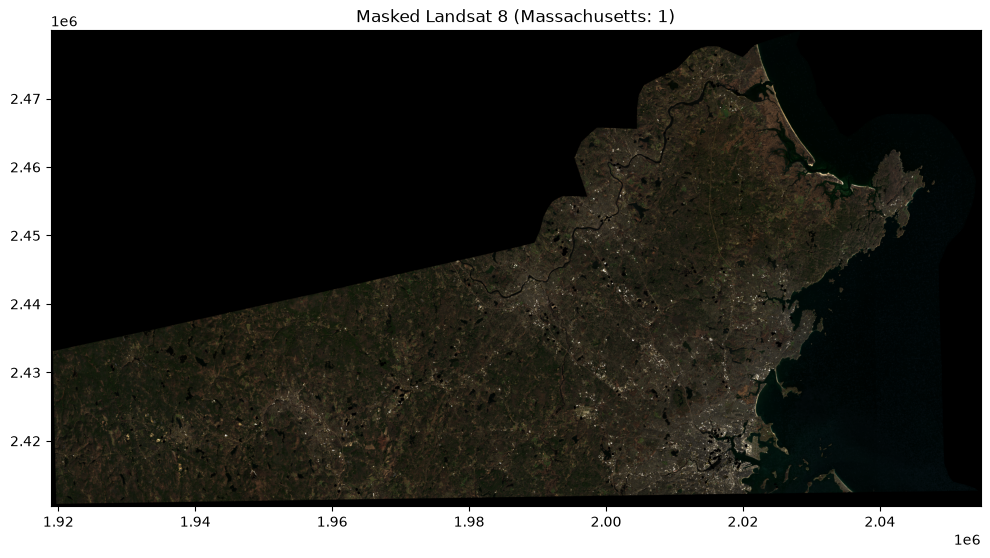

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.plot import show
from rasterio.plot import plotting_extent

with rasterio.open("data/satellite_images/LC08_012030_20201129.tif") as geotiff:
    data = geotiff.read(masked=True).astype(np.float32)

    # Convert NoData to NaN
    data = data.filled(np.nan)
    data[data == 0] = np.nan

    # Scale Landsat surface reflectance
    # NOTE: This displays the RGB reflectance colors
    data = data * 0.0000275 - 0.2

    # Convert (bands, height, width) to (height, width, bands)
    image = np.moveaxis(data, 0, -1)

    valid_mask = np.all(np.isfinite(image), axis=-1)
    extent = plotting_extent(geotiff)

# Extract RGB for visualization
rgb = image[:, :, [2, 1, 0]]
rgb = np.clip(rgb / 0.3, 0, 1)

# Display masked pixels as transparent
rgba = np.dstack([
    np.nan_to_num(rgb),
    valid_mask.astype(np.float32)
])

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor("black")
ax.imshow(rgba, extent=extent)
ax.set_title("Masked Landsat 8 (Massachusetts: 1)")
plt.show()

In [15]:
N = 64
height, width, bands = image.shape

def split_image(image, valid_mask, N):
    """
    Split an image into panels of NxN pixels.
    """

    height, width, bands = image.shape

    for row in range(0, height, N):
        for col in range(0, width, N):
            sub_image = image[row:row + N, col:col + N, :]
            sub_mask = valid_mask[row:row + N, col:col + N]

            yield sub_image, sub_mask, row, col

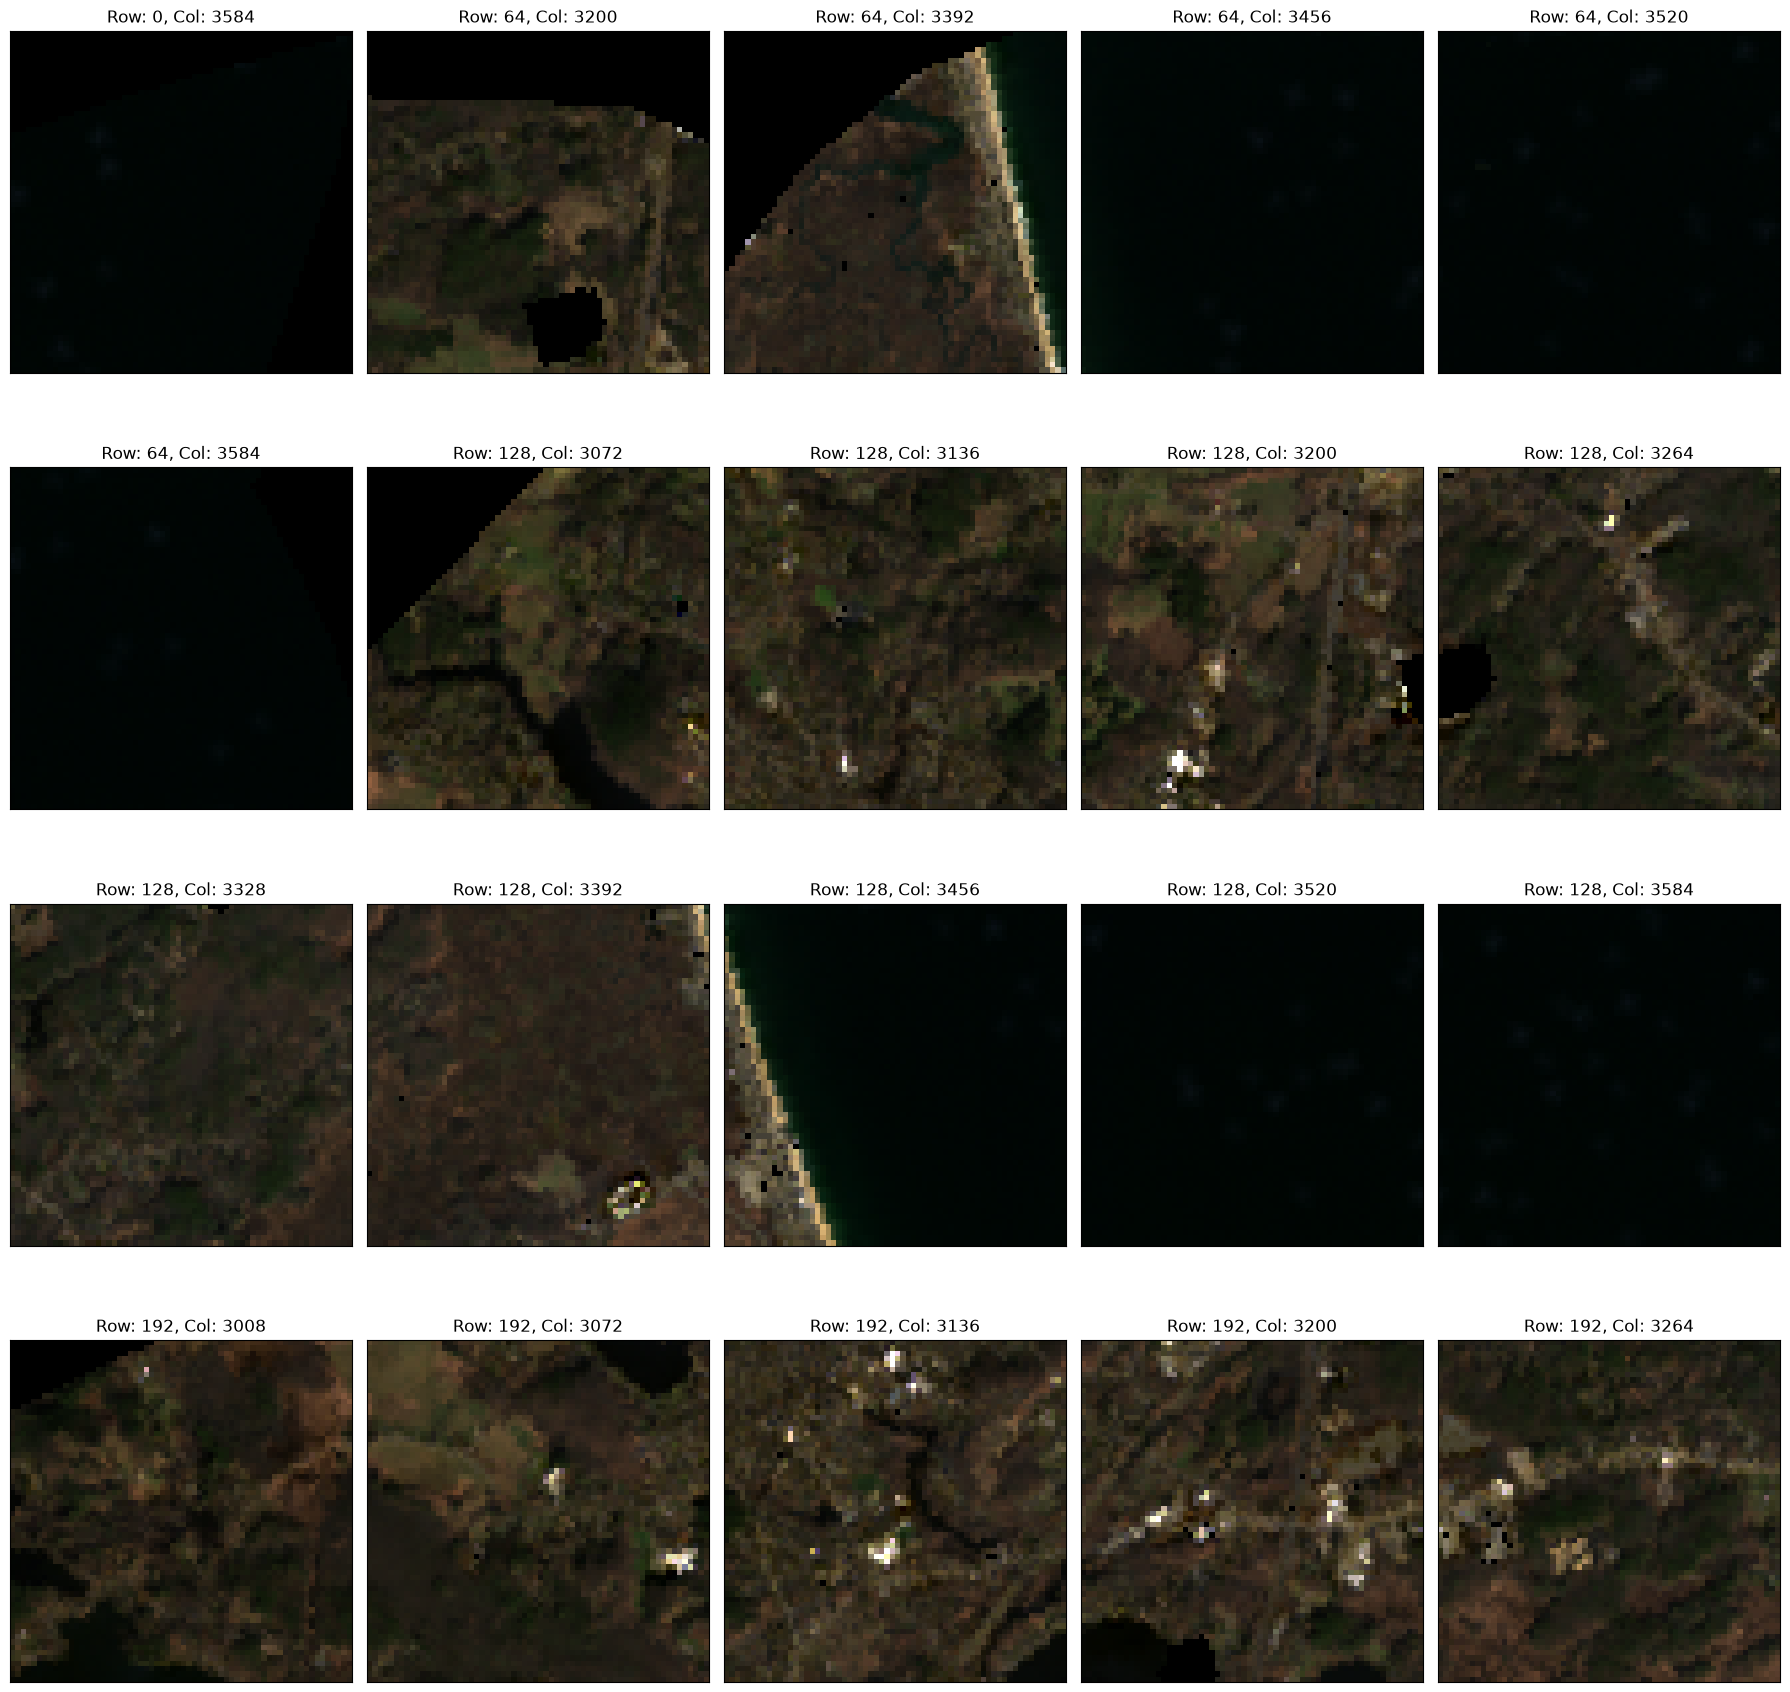

In [16]:
fig, axes = plt.subplots(4, 5, figsize=(18, 18))

# Generator for processing individual tiles
# NOTE: sub-image needs at least 70% coverage
tiles = (
    (sub_image, sub_mask, row, col)
    for sub_image, sub_mask, row, col
    in split_image(image, valid_mask, N)
    if sub_mask.mean() >= 0.70
)

# Plot a 5x5 grid of image tiles
for ax in axes.flat:
    tile = next(tiles, None)

    if tile is None:
        ax.axis("off")
        continue

    sub_image, sub_mask, row, col = tile

    rgb = sub_image[:, :, [2, 1, 0]]
    rgb = np.clip(rgb / 0.3, 0, 1)

    rgba = np.dstack([
        np.nan_to_num(rgb),
        sub_mask.astype(np.float32)
    ])

    ax.set_facecolor("black")
    ax.imshow(rgba, interpolation="nearest")
    ax.set_title(f"Row: {row}, Col: {col}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### Test 1: Spectral Reflectance

In this first test, the feature set is the spectral reflectance data. The idea is that the FEC model will cluster regions with the spectrum reflectance values, identifying features within the image.

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4092, 6)
Number of clusters: 5
Runtime: 40.84446640000169 seconds


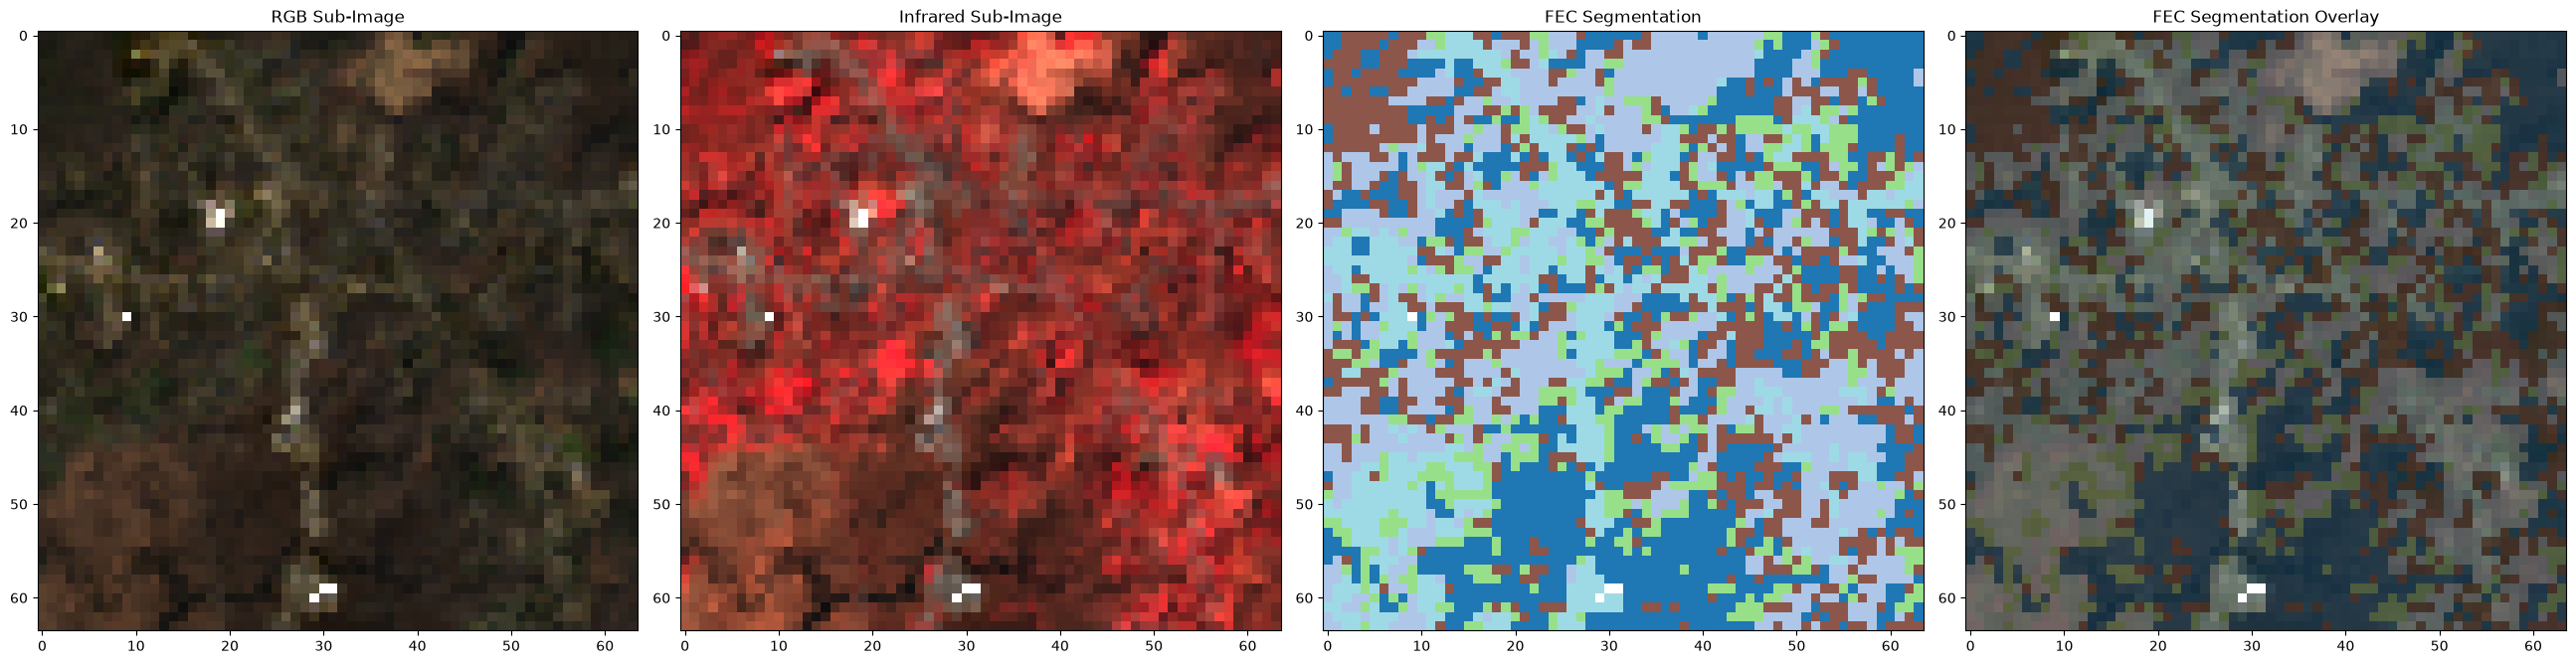

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4096, 6)
Number of clusters: 2
Runtime: 41.146809300000314 seconds


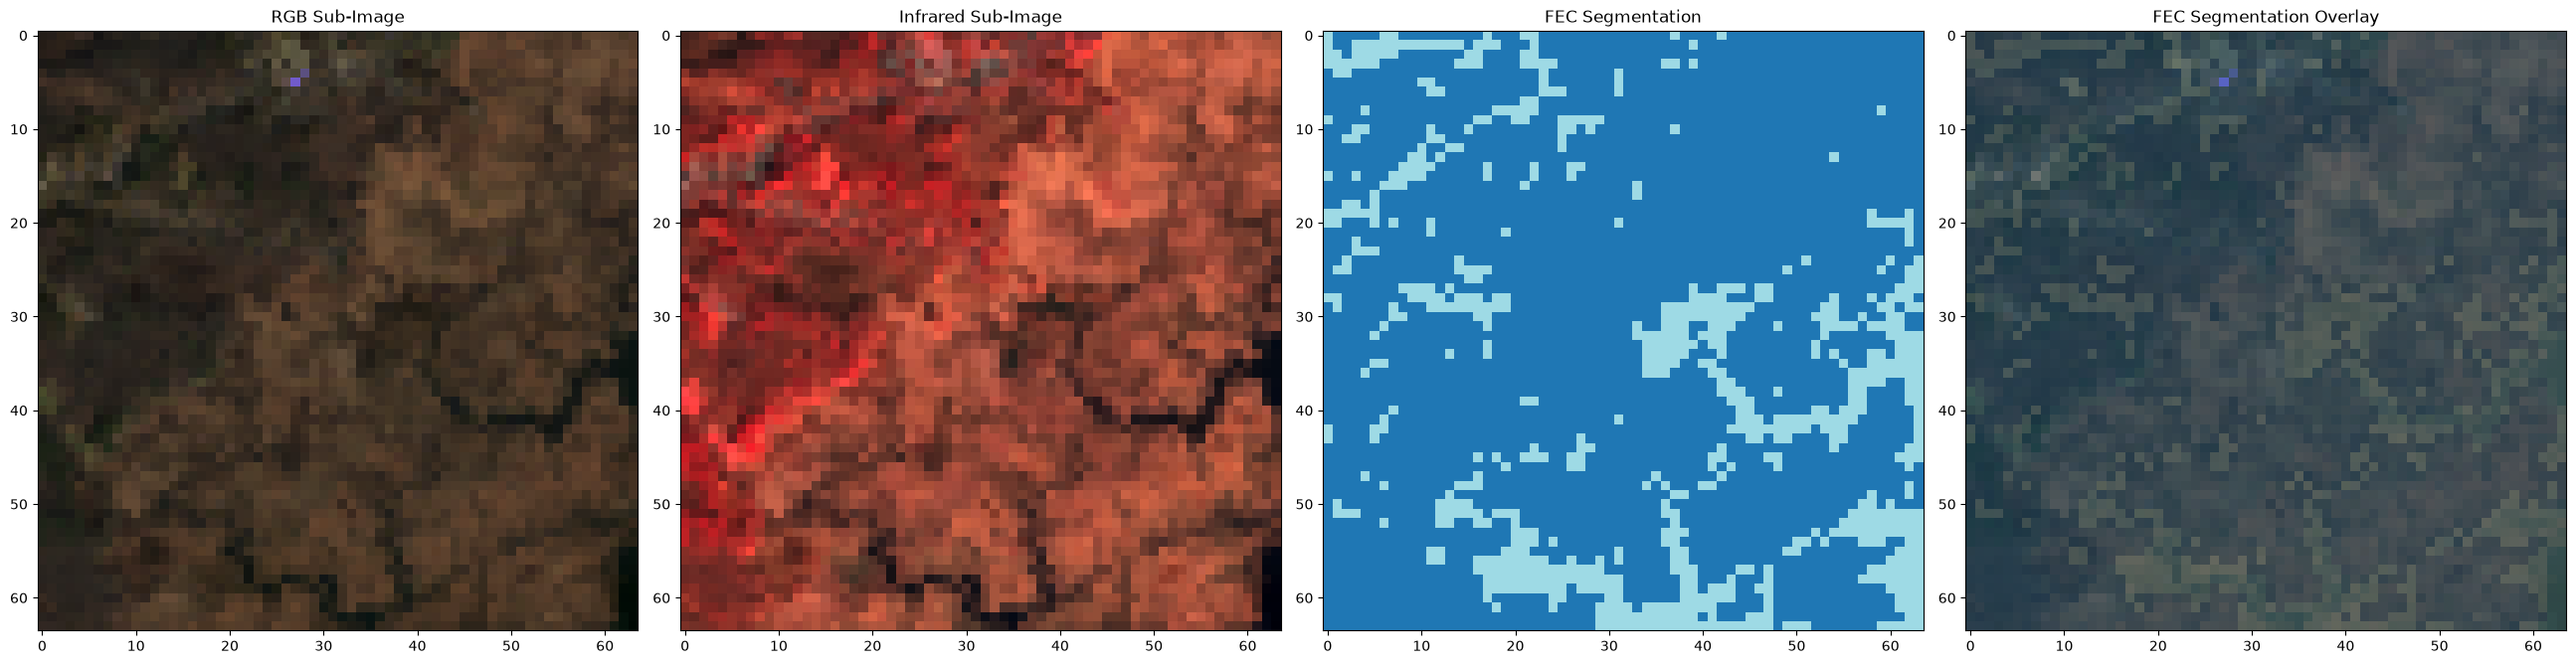

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4085, 6)
Number of clusters: 5
Runtime: 41.34324809999816 seconds


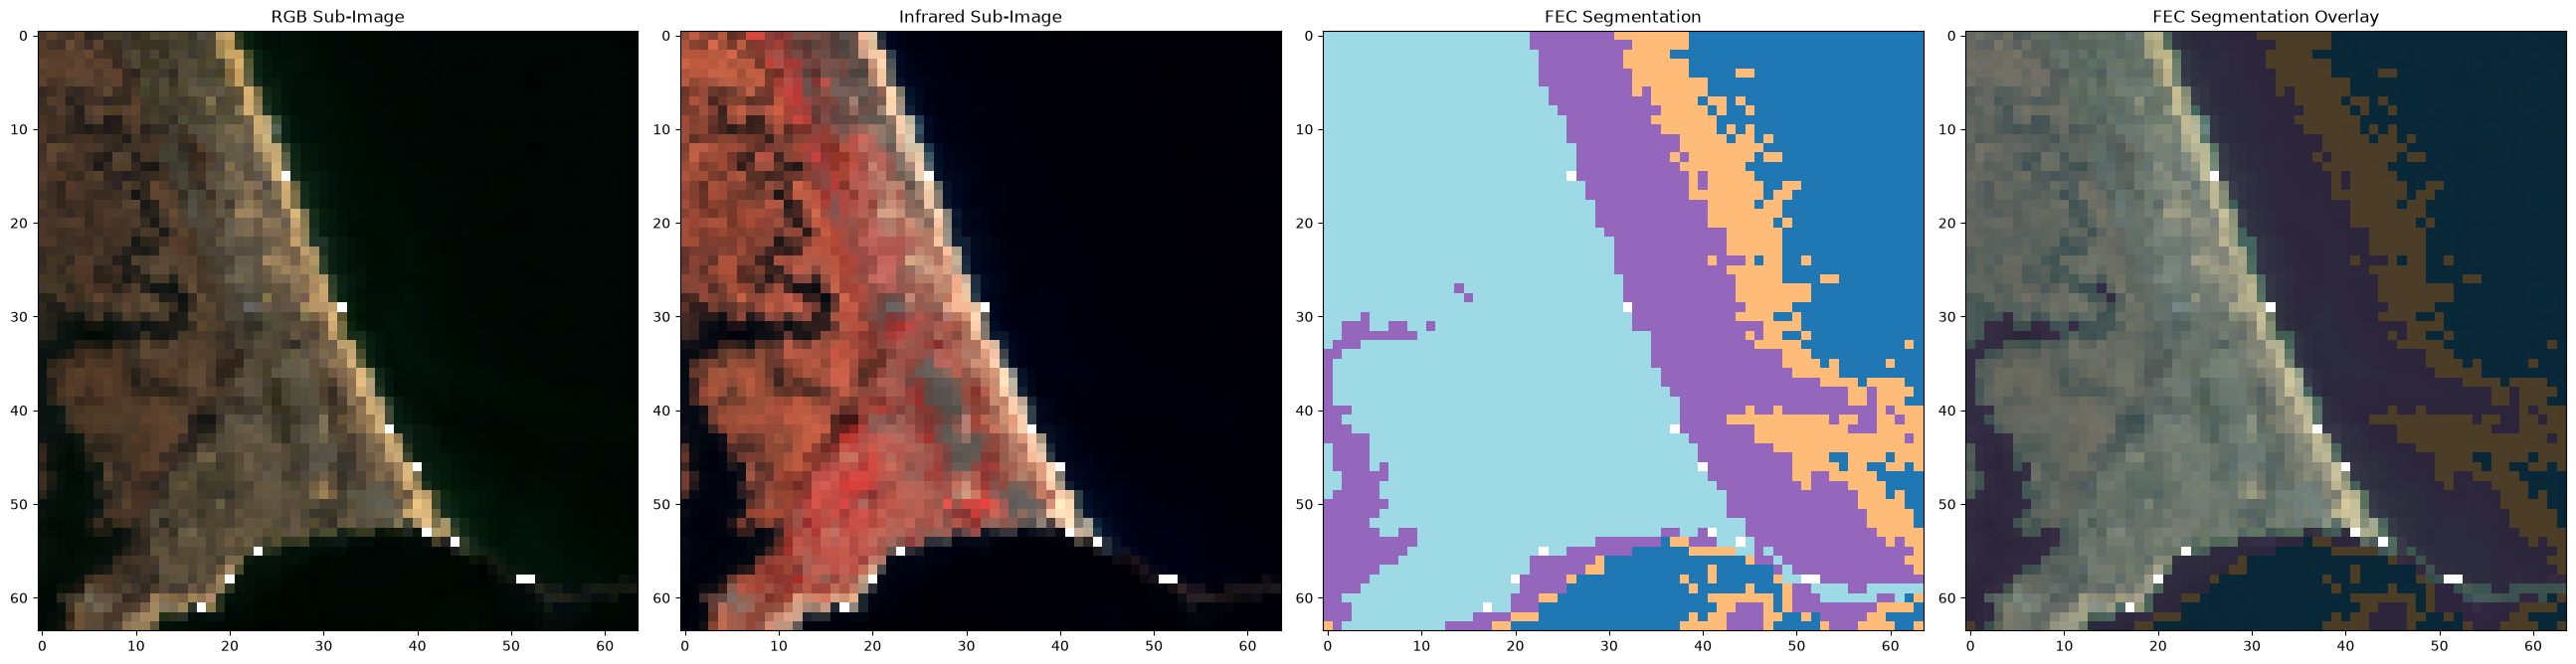

In [17]:
import time
from fec import FluxEquilibriumClustering

# Run N tests
N_TESTS = 3

test_tiles = [next(tiles) for _ in range(N_TESTS)]

for tile in test_tiles:
    # Extract individual test tile
    sub_image, sub_mask, row, col = tile

    # Extract the spectrum from the image
    spectral = sub_image[sub_mask]

    # Create feature matrix
    X = spectral

    fec = FluxEquilibriumClustering(
        k=8,
        sigma=None,
        alpha=0.5,
        T=50,
        epsilon=1e-4,
        beta=None
    )

    start = time.perf_counter()
    labels = fec.fit_predict(X)
    elapsed = time.perf_counter() - start

    segmented_tile = np.full(
        sub_mask.shape,
        -1,
        dtype=np.int32
    )

    segmented_tile[sub_mask] = labels

    print("Sub-image shape:", sub_image.shape)
    print("Feature matrix shape:", X.shape)
    print("Number of clusters:", len(np.unique(labels)))
    print("Runtime:", elapsed, "seconds")

    fig, axes = plt.subplots(1, 4, figsize=(26, 10))

    # RGB spectrum
    rgb = np.clip(sub_image[:, :, [2, 1, 0]] / 0.3, 0, 1)
    rgba = np.dstack([
        np.nan_to_num(rgb),
        sub_mask.astype(np.float32)
    ])

    # Near-infrared spectrum
    infrared = np.clip(sub_image[:, :, [3, 2, 1]] / 0.3, 0, 1)
    infrared_rgba = np.dstack([
        np.nan_to_num(infrared),
        sub_mask.astype(np.float32)
    ])

    seg = np.ma.masked_equal(segmented_tile, -1)

    # Original RGB image
    axes[0].imshow(rgba, interpolation="nearest")
    axes[0].set_title("RGB Sub-Image")

    # Infrared image
    axes[1].imshow(infrared_rgba, interpolation="nearest")
    axes[1].set_title("Infrared Sub-Image")

    # Segmentation
    axes[2].imshow(
        seg,
        cmap="tab20",
        interpolation="nearest"
    )
    axes[2].set_title("FEC Segmentation")

    # Transparent segmentation overlay
    axes[3].imshow(rgba, interpolation="nearest")
    axes[3].imshow(
        seg,
        cmap="tab20",
        interpolation="nearest",
        alpha=0.30
    )
    axes[3].set_title("FEC Segmentation Overlay")

    plt.tight_layout()
    plt.show()

From the (promising) results above, the FEC model can learn general features from the image, but has some significant issues. First, there is to spatial awareness for the model to learn, hence any region (regardless of location) with the same spectral reflectance can belong to the same cluster. Secondly, the model is somewhat prone to learning noise due to large changes in adjacent pixel colors in the RGB and infared spectrums.

The model is good at segmenting the image based on large geographical features. In the first and second images, the model learned to segment large regions of similar land masses. In the RRB and infared spectrums, there are large plots of land that appear to have the same properties. In the second image, the model excelled at seperating the land mass, shallow water (coastal ocean and bay/river), and deep water.

The next test attempts to address these issues by adding a spatial feature to the feature matrix.

### Test 2: Spatial Clustering

This test adds a spatial feature to the feature matrix. The spatial feature is defined as the pixel location in the tile.

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4092, 8)
Number of clusters: 3
Runtime: 42.09699439999895 seconds


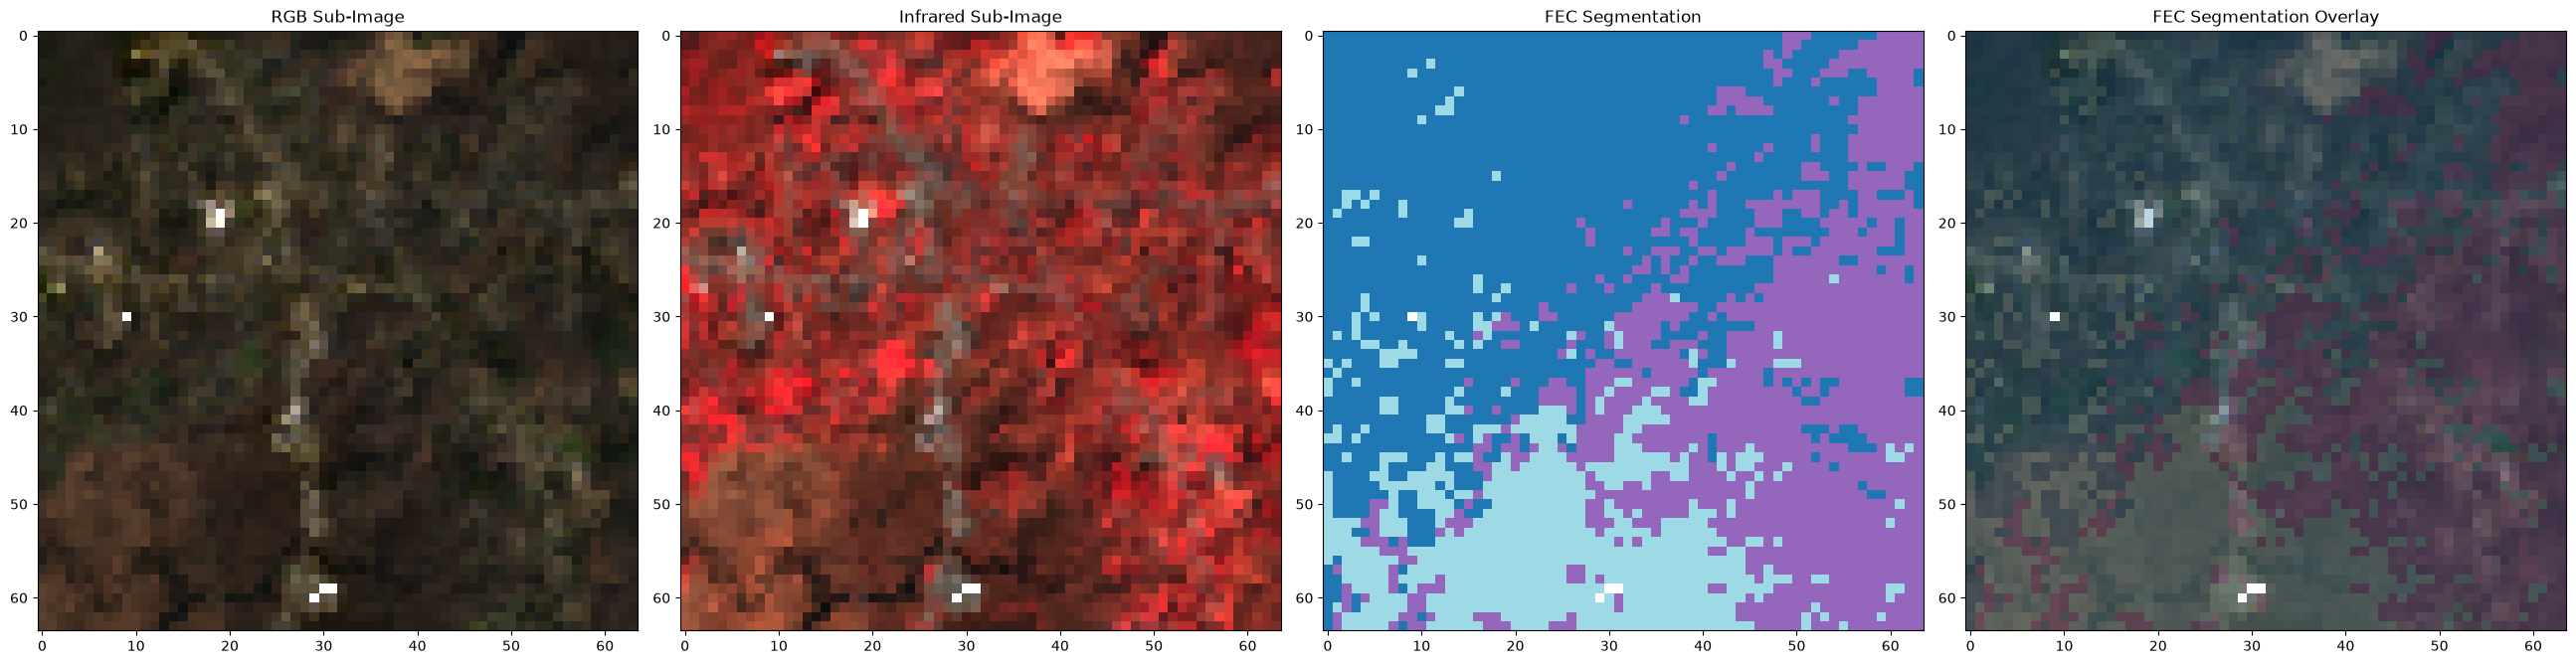

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4096, 8)
Number of clusters: 3
Runtime: 42.1679312999986 seconds


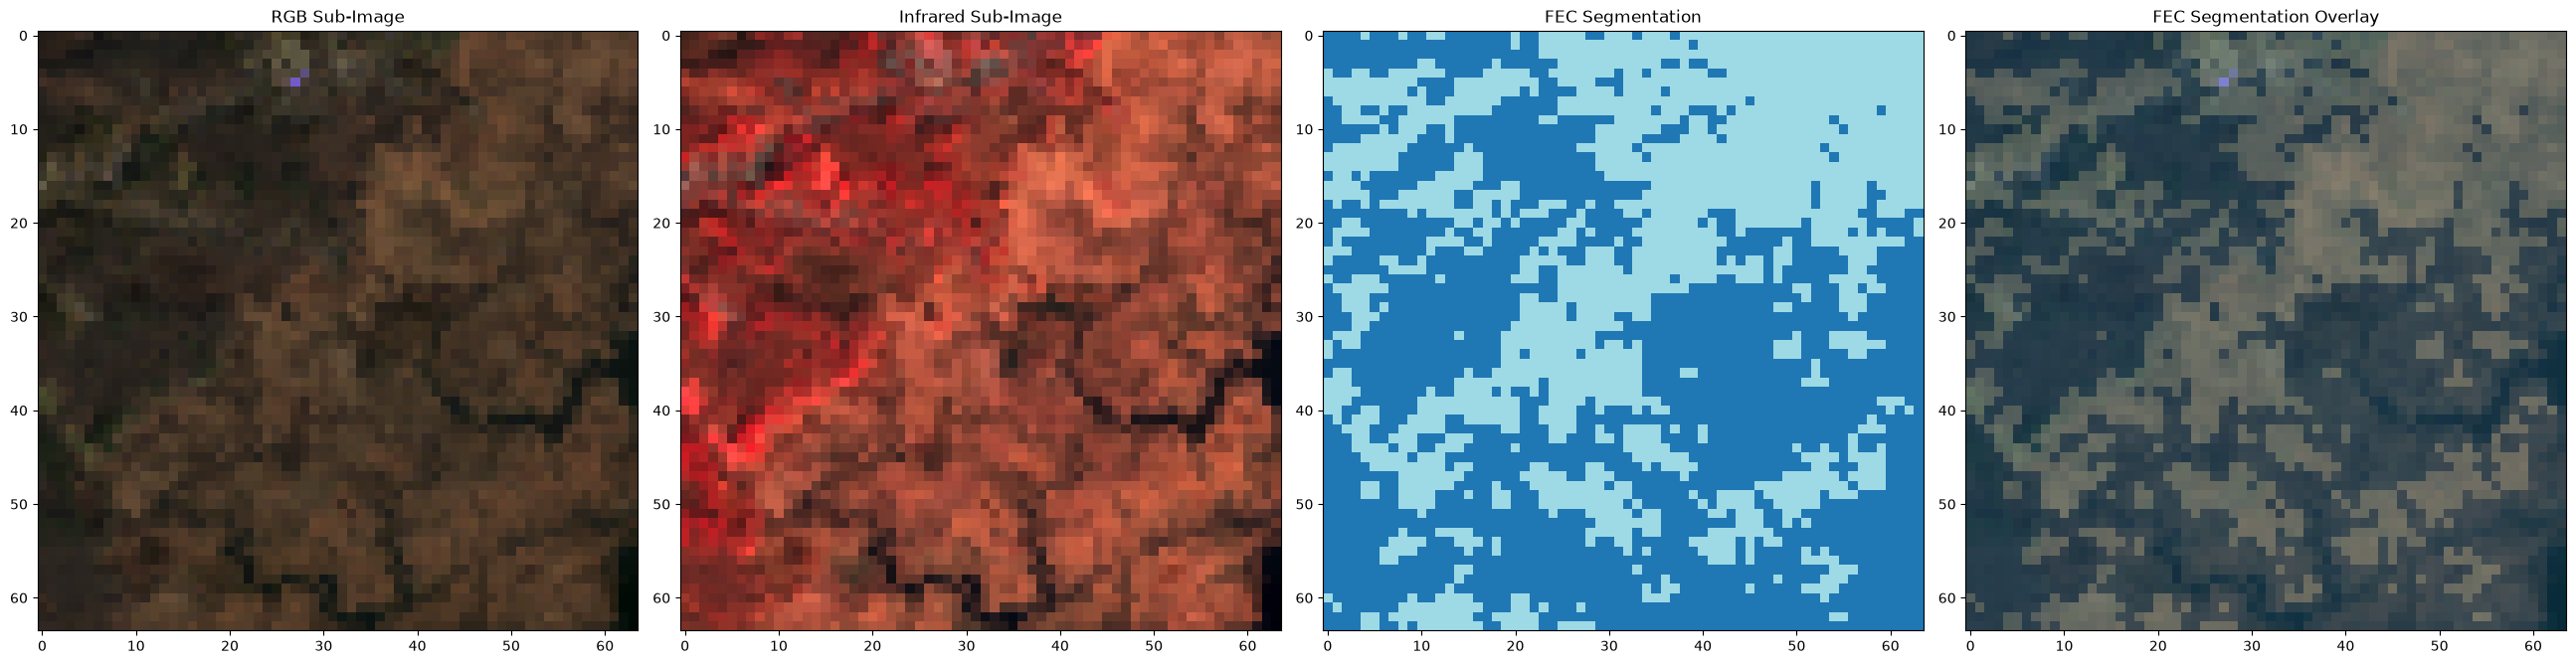

Sub-image shape: (64, 64, 6)
Feature matrix shape: (4085, 8)
Number of clusters: 16
Runtime: 40.19095659999948 seconds


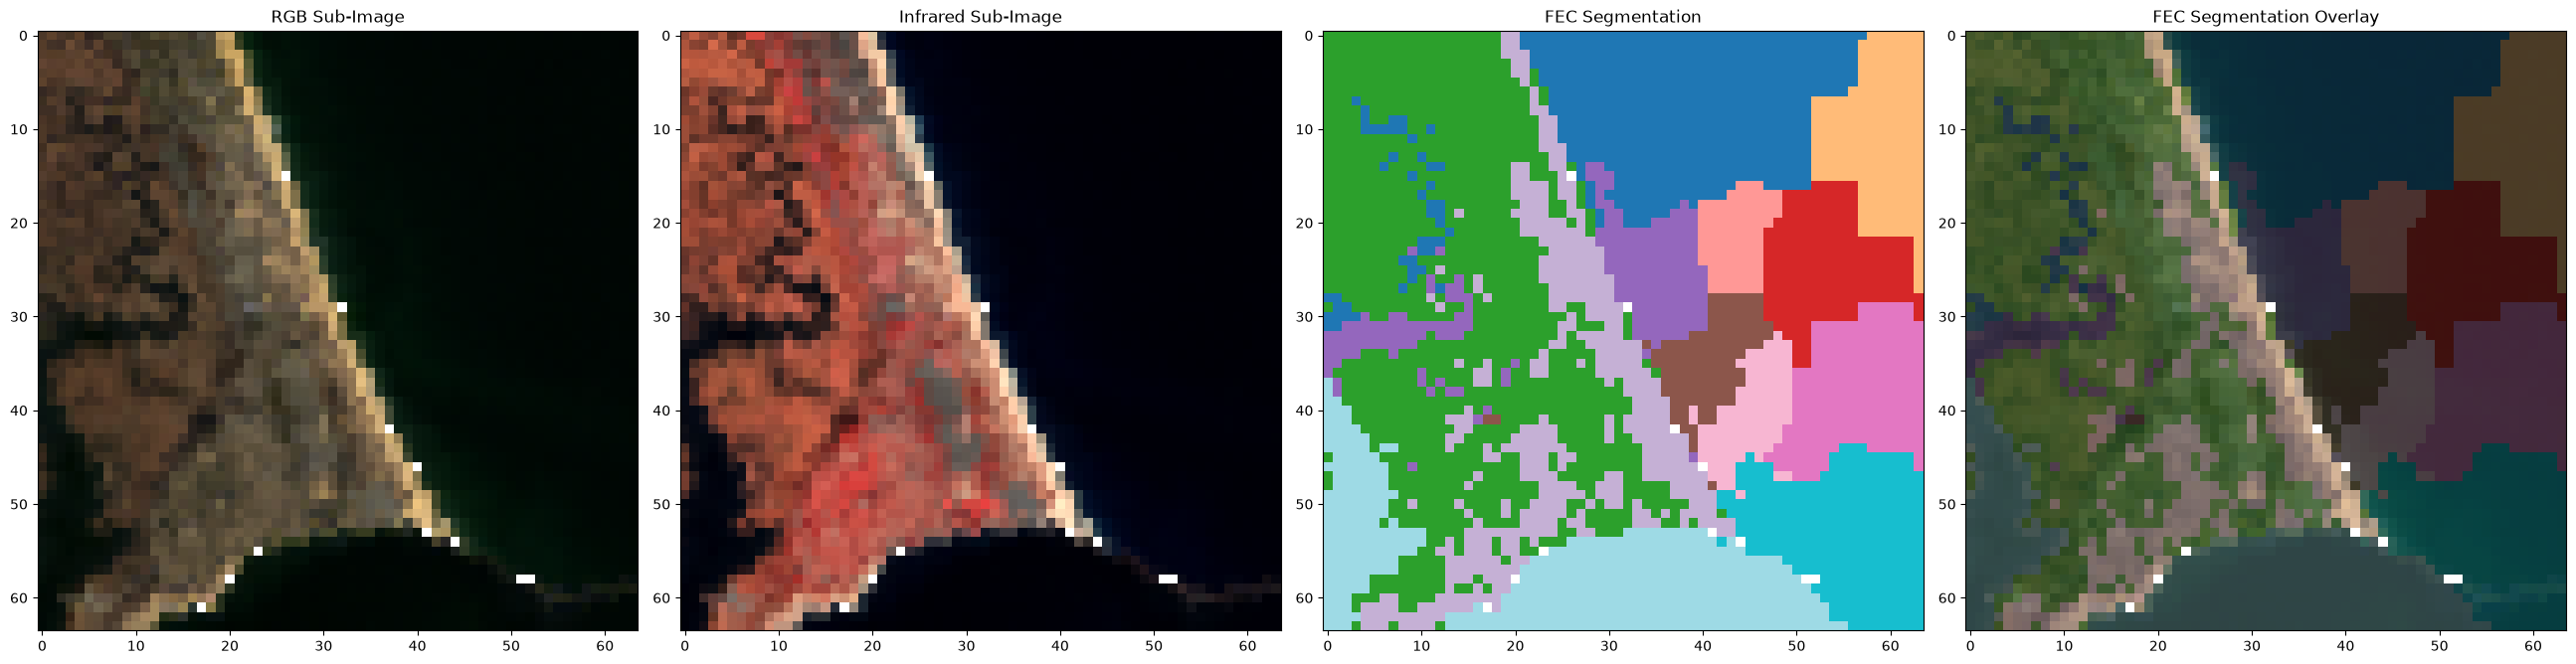

In [18]:
SPATIAL_INFLUENCE = 0.2

for tile in test_tiles:
    # Extract individual test tile
    sub_image, sub_mask, row, col = tile

    # Extract the spectrum from the image
    spectral = sub_image[sub_mask]

    # Extract spatial location
    rows, cols = np.indices(sub_mask.shape)
    spatial = np.column_stack([
        rows[sub_mask],
        cols[sub_mask]
    ]) / N

    # Create feature matrix
    X = np.column_stack([
        spectral,
        spatial * SPATIAL_INFLUENCE
    ])

    fec = FluxEquilibriumClustering(
        k=8,
        sigma=None,
        alpha=0.5,
        T=50,
        epsilon=1e-4,
        beta=None
    )

    start = time.perf_counter()
    labels = fec.fit_predict(X)
    elapsed = time.perf_counter() - start

    segmented_tile = np.full(
        sub_mask.shape,
        -1,
        dtype=np.int32
    )

    segmented_tile[sub_mask] = labels

    print("Sub-image shape:", sub_image.shape)
    print("Feature matrix shape:", X.shape)
    print("Number of clusters:", len(np.unique(labels)))
    print("Runtime:", elapsed, "seconds")

    fig, axes = plt.subplots(1, 4, figsize=(26, 10))

    # RGB spectrum
    rgb = np.clip(sub_image[:, :, [2, 1, 0]] / 0.3, 0, 1)
    rgba = np.dstack([
        np.nan_to_num(rgb),
        sub_mask.astype(np.float32)
    ])

    # Near-infrared spectrum
    infrared = np.clip(sub_image[:, :, [3, 2, 1]] / 0.3, 0, 1)
    infrared_rgba = np.dstack([
        np.nan_to_num(infrared),
        sub_mask.astype(np.float32)
    ])

    seg = np.ma.masked_equal(segmented_tile, -1)

    # Original RGB image
    axes[0].imshow(rgba, interpolation="nearest")
    axes[0].set_title("RGB Sub-Image")

    # Infrared image
    axes[1].imshow(infrared_rgba, interpolation="nearest")
    axes[1].set_title("Infrared Sub-Image")

    # Segmentation
    axes[2].imshow(
        seg,
        cmap="tab20",
        interpolation="nearest"
    )
    axes[2].set_title("FEC Segmentation")

    # Transparent segmentation overlay
    axes[3].imshow(rgba, interpolation="nearest")
    axes[3].imshow(
        seg,
        cmap="tab20",
        interpolation="nearest",
        alpha=0.30
    )
    axes[3].set_title("FEC Segmentation Overlay")

    plt.tight_layout()
    plt.show()

## Conculusion

The results, after including a spatial feature, improve the FEC clustering significantly. Compared to the first (non-spatial) test, the FEC model now clusters the land features within the same local region. This can be seen most readily in the first and third images. Including the spatial feature significantly reduced the noise in the labels and isolated image segments within the same regions.

### Improvements
- Expanding to many more images (possibly larger images)
- Hyperparameter tuning
- Optimal spatial influence